In [1]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
from scipy.signal import hilbert, find_peaks

from pathlib import Path
from data_io.lussm_dataset import LUSSMDataset

In [2]:
folder = r'C:\Users\W\Desktop\MASTERRRRRRR\AA THESIS\data\LU_data\20261027\data'
dataset = LUSSMDataset(folder)
dataset_number = 3
data = dataset.data['Time'][dataset_number -1 ]

In [3]:
a_scan = data.time_data
spectrum = data.fft_data
t_array = data.t_array
f_array = data.f_array
nt = data.nt
nf = data.nf

Filtering in Freq domain:

Hardware filter: 1MHz (under this not relyable capturing)
Digital filter: 150% bandwidth of central frequency
For waveform 19: 23ns  --> 

In [4]:
# 3. Create the filter
f_low = 1.50e6
f_high = 12.0e6
order = 4
low_ratio = np.abs(f_array) / f_low
H_low = low_ratio ** (2 * order) / np.sqrt(1 + low_ratio ** (4 * order))
H_high = 1 / np.sqrt(1 + (np.abs(f_array) / f_high) ** (4 * order))
H = H_low * H_high

# 4. Filter the single A-scan
spectrum_filtered = spectrum * H
a_scan_filtered = np.fft.ifft(np.fft.ifftshift(spectrum_filtered), n=nf)

spectrum_removed = spectrum - spectrum_filtered
a_scan_removed = np.fft.ifft(np.fft.ifftshift(spectrum_removed), n=nf)

# Compute the analytic signal over measured samples, excluding FFT zero-padding
analytic_a_scan = hilbert(np.real(a_scan_filtered[:nt]))
a_scan_envelope = np.abs(analytic_a_scan)

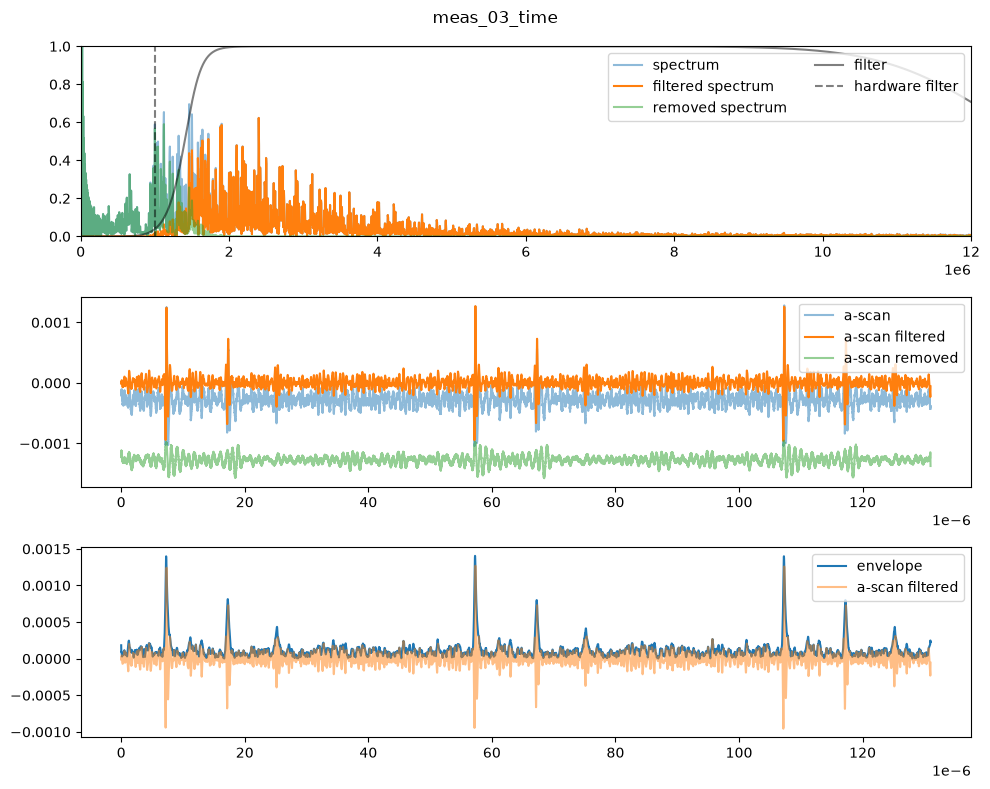

In [5]:
plt.figure(1, figsize=(10, 8))
plt.clf()

plt.subplot(311)
plt.plot(f_array, np.abs(spectrum), color='C0', alpha=0.5, label='spectrum')
plt.plot(f_array, np.abs(spectrum_filtered), color='C1', label='filtered spectrum')
plt.plot(f_array, np.abs(spectrum_removed), color='C2', alpha=0.5, label='removed spectrum')
plt.plot(f_array, H, color='k', alpha=0.5, label='filter')
plt.vlines(1e6, -1, 1, color='k', ls='--', alpha=0.5, label='hardware filter')

plt.xlim(0.0, 12e6)
plt.ylim(0.0, 1)
plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(6, 6))
plt.legend(loc='upper right', ncols=2)

plt.subplot(312)
plt.plot(t_array, a_scan, color='C0', alpha=0.5, label='a-scan')
plt.plot(t_array, np.real(a_scan_filtered[:nt]), color='C1', label='a-scan filtered')
plt.plot(t_array, np.real(a_scan_removed[:nt])  -0.001, color='C2', alpha=0.5, label='a-scan removed')

plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(-6, -6))
plt.legend(loc='upper right')

plt.subplot(313)
plt.plot(t_array, a_scan_envelope[:nt], color='C0', label='envelope')
plt.plot(t_array, np.real(a_scan_filtered[:nt]), color='C1', alpha=0.5, label='a-scan filtered')

plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(-6, -6))
plt.legend(loc='upper right')

plt.suptitle(data.filename)
plt.tight_layout()
plt.show()

Find the repeated surface-wave peaks in the envelope, then place each cycle boundary at the steepest rising slope just before a peak.



Cycle starts at 57.188 us
Cycle duration: 49.992 us
Repeated peak spacings (us): [49.992]


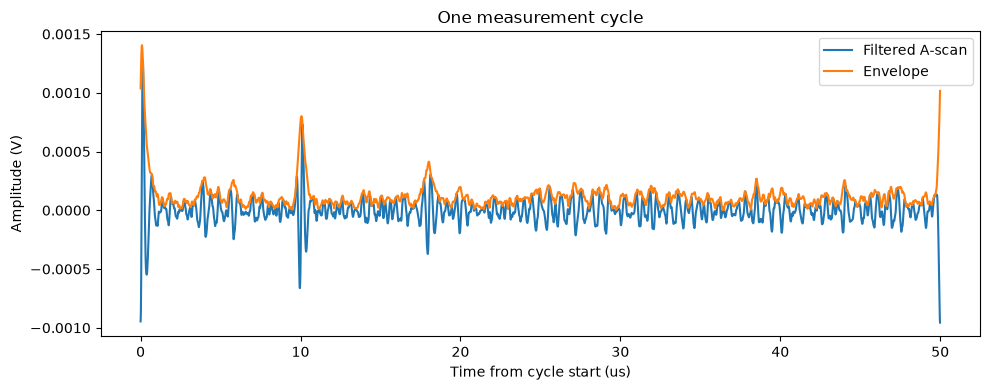

In [6]:
f_sampling = data.sampling_frequency
amplitude_envelope = a_scan_envelope

# Keep the strong surface-wave peaks and skip smaller echoes within each cycle.
peak_threshold = 0.99 * np.max(amplitude_envelope)
minimum_peak_spacing = int(40e-6 * f_sampling)
peak_indices, _ = find_peaks(
    amplitude_envelope,
    height=peak_threshold,
    prominence=peak_threshold,
    distance=minimum_peak_spacing,
)
if len(peak_indices) < 2:
    raise ValueError("Could not find two repeated surface-wave peaks to define a cycle.")

# Use the strongest rising slope immediately before each peak as the trigger.
envelope_slope = np.gradient(amplitude_envelope, t_array)
rise_window = int(2e-6 * f_sampling)
start_indices = []
for peak_index in peak_indices:
    rise_start = max(0, peak_index - rise_window)
    start_indices.append(
        rise_start + np.argmax(envelope_slope[rise_start : peak_index + 1])
    )
start_indices = np.asarray(start_indices)

# Slice one measured cycle, from the first trigger to the next one.
cycle_start = start_indices[0]
cycle_end = start_indices[1]
single_cycle_time = t_array[cycle_start:cycle_end] - t_array[cycle_start]
single_cycle_signal = np.real(a_scan_filtered[cycle_start:cycle_end])
single_cycle_envelope = amplitude_envelope[cycle_start:cycle_end]
cycle_duration = t_array[cycle_end] - t_array[cycle_start]

print(f"Cycle starts at {t_array[cycle_start] * 1e6:.3f} us")
print(f"Cycle duration: {cycle_duration * 1e6:.3f} us")
print(f"Repeated peak spacings (us): {np.diff(t_array[start_indices]) * 1e6}")

plt.figure(figsize=(10, 4))
plt.plot(single_cycle_time * 1e6, single_cycle_signal, label="Filtered A-scan")
plt.plot(single_cycle_time * 1e6, single_cycle_envelope, label="Envelope")
plt.xlabel("Time from cycle start (us)")
plt.ylabel("Amplitude (V)")
plt.title("One measurement cycle")
plt.legend()
plt.tight_layout()
